# 02. Tabela compartilhada dos modelos (`serie`)

Etapa 2 do fluxo: `01_download.ipynb` → **`02_serie_modelos.ipynb`** → `03_guia_bases_modelos.ipynb` → entradas de cada modelo (`04_entradas_modelo1_gp.ipynb`, `05_entradas_modelo2_rgp.ipynb`, `06_entradas_modelo3_gplvm.ipynb`) → notebooks dos modelos (`07`–`09`).

Este notebook monta a `serie` (uma linha por estação e dia) a partir dos arquivos do `01_download.ipynb`, **salva uma única vez** em `data/exports/` e faz as conferências da base. Os notebooks dos modelos **só leem** o arquivo salvo, para que os três modelos tenham as mesmas estações, os mesmos dias escondidos, a mesma normalização e os mesmos rótulos.

Por que salvar uma vez: os dias escondidos são sorteados por um único gerador que percorre as estações em sequência. Montar a `serie` de novo com outra seleção de estações muda os dias escondidos de cada estação.

Nenhuma célula consulta a API.

## 1. Carregar os módulos

In [1]:
from dataclasses import asdict
import json
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_project_root(start: Path) -> Path:
    for folder in (start.resolve(), *start.resolve().parents):
        if (folder / "src" / "main.py").is_file() and (folder / "data" / "usgs").is_dir():
            return folder
    raise FileNotFoundError("Não encontrei src/main.py e data/usgs. Abra o notebook na pasta do projeto.")

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import USGS, EXPORT_ROOT
from src.main import build_model_dataset, default_download_config
from src.download import load_selected
from src.model_data import PROBLEM_QUALIFIERS, SelectionConfig, SplitConfig, split_summary

print(f"Projeto: {PROJECT_ROOT}")
print(f"Parâmetro: {USGS.parameter_code} | estatística: {USGS.statistic_id} | "
      f"período: {USGS.date_start} a {USGS.date_end}")

Projeto: C:\Users\aliss\OneDrive\Repositorios\usgs_streamflow
Parâmetro: 00060 | estatística: 00003 | período: 2010-01-01 a 2025-12-31


## 2. Configurações

`SELECAO` escolhe as estações (filtros calculados só no treino) e `SPLITS` define os blocos, os dias escondidos e a transformação. Os argumentos estão explicados na seção 2 do `03_guia_bases_modelos.ipynb`.

`NOME` identifica a base. **Para mudar `SELECAO` ou `SPLITS`, troque também `NOME`**: a base antiga continua no disco, e a nova é salva com outro nome. Os notebooks dos modelos precisam usar o mesmo `NOME`.

In [2]:
SELECAO = SelectionConfig(
    n_sensors=200,           # quantas estações entram na serie
    min_completeness=0.95,   # fração mínima de dias com valor no treino
    max_zero_frac=0.05,      # fração máxima de vazão zero no treino (exclui rios intermitentes)
    candidates=None,         # ou uma tupla de IDs para restringir a escolha
    seed=42,
)
SPLITS = SplitConfig(fracs=(0.60, 0.15, 0.10, 0.15), hidden_frac=0.10, hidden_block_len=1, seed=42)

NOME = "serie_2010_2025_200est"

serie_path = EXPORT_ROOT / f"{NOME}.parquet"          # a tabela
stats_path = EXPORT_ROOT / f"{NOME}_stats.csv"        # média e desvio por estação (desfaz a normalização)
config_path = EXPORT_ROOT / f"{NOME}_config.json"     # configurações usadas para gerar a tabela

## 3. Montar e salvar (ou carregar, se já existir)

- **Primeira execução:** monta a `serie` e salva os três arquivos.
- **Execuções seguintes:** lê os arquivos do disco. Se as configurações acima forem diferentes das salvas em `_config.json`, a célula para com erro em vez de misturar bases: troque `NOME` para gerar uma base nova.

In [3]:
# Configurações atuais em formato JSON (tuplas viram listas)
config_atual = json.loads(json.dumps({
    "selecao": asdict(SELECAO),
    "splits": asdict(SPLITS),
    "periodo": [USGS.date_start, USGS.date_end],
    "parametro": USGS.parameter_code,
    "estatistica": USGS.statistic_id,
}))

if serie_path.exists():
    config_salva = json.loads(config_path.read_text(encoding="utf-8"))
    if config_salva != config_atual:
        raise ValueError(
            f"A base '{NOME}' já existe com outras configurações. Troque NOME para gerar uma base nova.\n"
            f"Salva: {config_salva}\nAtual: {config_atual}"
        )
    serie = pd.read_parquet(serie_path)
    stats = pd.read_csv(stats_path, index_col="sensor_id")
    print(f"Base já existente, lida de {serie_path}")
else:
    # Lê os arquivos do 01_download.ipynb (data/usgs/raw/parquets/) e monta a tabela
    serie, stats = build_model_dataset(SELECAO, SPLITS)
    EXPORT_ROOT.mkdir(parents=True, exist_ok=True)
    serie.to_parquet(serie_path, index=False)
    stats.to_csv(stats_path)
    config_path.write_text(json.dumps(config_atual, indent=2, ensure_ascii=False), encoding="utf-8")
    print(f"Base montada e salva em {EXPORT_ROOT}")

print(f"{len(serie):,} linhas | {serie['sensor_id'].nunique()} estações")
display(split_summary(serie))

Base montada e salva em C:\Users\aliss\OneDrive\Repositorios\usgs_streamflow\data\exports
1,168,800 linhas | 200 estações


,inicio,fim,linhas,visiveis,escondidos,anomalias,provisorios
split,,,,,,,
treino,2010-01-01,2019-08-07,701200,700629,0,2951,0
validacao,2019-08-08,2021-12-31,175400,154718,16993,525,0
calibracao,2022-01-01,2023-08-07,116800,103270,11342,417,0
teste,2023-08-08,2025-12-31,175400,148467,16305,862,5138


O resumo mostra, por bloco, o período, quantos dias os modelos podem usar (`visiveis`), quantos foram escondidos para medir a reconstrução, quantos têm qualificador de problema (`anomalias`) e quantos são provisórios. **Confira se `validacao`, `calibracao` e `teste` têm anomalias**: sem elas, as métricas de detecção ficam vazias.

## 4. Conferências da base

### 4.1 Rótulos de anomalia

`PROBLEM_QUALIFIERS` (em `src/model_data.py`) define quais qualificadores viram `anomalia = 1`. A tabela mostra os textos reais e se cada um vira anomalia.

In [4]:
print("PROBLEM_QUALIFIERS:", PROBLEM_QUALIFIERS)
display(serie["aprovacao"].value_counts(dropna=False).rename("dias").to_frame())
display(
    serie.groupby("qualificador")["anomalia"].agg(dias="size", vira_anomalia="max")
    .sort_values("dias", ascending=False).head(20)
)

PROBLEM_QUALIFIERS: \b(?:eqp|equip\w*|ice|bkw|backwater|mnt|maint\w*|fld|flood\w*)\b


,dias
aprovacao,
Approved,1147153
,16509
Provisional,5138


,dias,vira_anomalia
qualificador,,
,1034942,0
ESTIMATED,124870,0
REVISED,2617,0
ESTIMATED;ICE,2077,1
ICE,1359,1
EQUIP;ESTIMATED,916,1
ESTIMATED;REVISED,643,0
FORCEINTERPOLATION,463,0
RATINGDEV,255,0


### 4.2 Anomalias por estado e bloco

Mostra onde estão os rótulos. Estados frios (rótulo `ICE`) concentram anomalias; um estado sem anomalias num bloco não contribui para a avaliação daquele bloco.

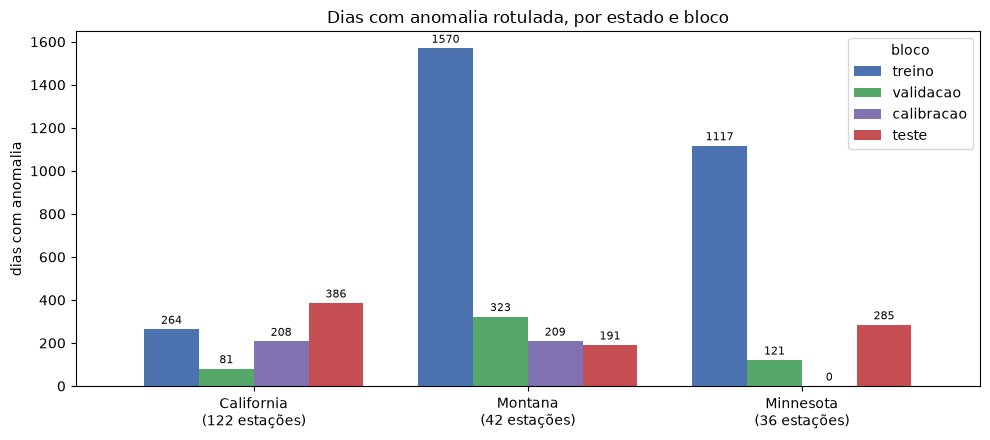

In [5]:
ordem = ["treino", "validacao", "calibracao", "teste"]
cores = {"treino": "#4C72B0", "validacao": "#55A868", "calibracao": "#8172B2", "teste": "#C44E52"}

# Estado de cada estação (vem da seleção feita no 01_download.ipynb)
estado = load_selected(default_download_config()).set_index("monitoring_location_id")["state_name"]

anom = (serie[serie["anomalia"] == 1]
        .assign(estado=lambda d: d["sensor_id"].astype(str).map(estado))
        .groupby(["estado", "split"]).size()
        .unstack("split").reindex(columns=ordem).fillna(0).astype(int))

# Número de estações de cada estado na serie
n_est = serie.groupby("sensor_id")["sensor_id"].first().astype(str).map(estado).value_counts()
anom = anom.reindex(n_est.index, fill_value=0)
anom.index = [f"{e}\n({n_est[e]} estações)" for e in anom.index]

ax = anom.plot.bar(color=[cores[s] for s in ordem], figsize=(10, 4.5), width=0.8, rot=0)
for c in ax.containers:
    ax.bar_label(c, fontsize=8, padding=2)
ax.set(title="Dias com anomalia rotulada, por estado e bloco", xlabel="", ylabel="dias com anomalia")
ax.legend(title="bloco")
plt.tight_layout()
plt.show()

### 4.3 Cobertura por estação e bloco

Os filtros de seleção só olham o treino. Uma estação pode estar completa no treino e quase vazia depois. Fora do treino, cerca de 0,90 de dias visíveis é o máximo esperado (10% são escondidos de propósito). Nas estações listadas, a avaliação da reconstrução fica limitada; mantenha-as e declare a limitação, ou retire-as da análise declarando o critério.

In [6]:
por_bloco = (serie.groupby(["sensor_id", "split"])
             .agg(dias=("t", "size"), visiveis=("visivel", "sum"),
                  escondidos=("escondido_aval", "sum"), anomalias=("anomalia", "sum")))

cobertura = (por_bloco["visiveis"] / por_bloco["dias"]).unstack()[ordem].round(2)   # fração visível
escondidos = por_bloco["escondidos"].unstack()[ordem]
anomalias = por_bloco["anomalias"].unstack()[ordem]

display(cobertura.describe().round(2))

# Estações com algum bloco abaixo de 50% visível ou sem dias escondidos no teste
problemas = cobertura[(cobertura < 0.5).any(axis=1) | (escondidos["teste"] == 0)]
print(f"{len(problemas)} estações com cobertura baixa fora do treino:")
display(problemas)

split,treino,validacao,calibracao,teste
count,200.00,200.00,200.00,200.00
mean,1.00,0.88,0.88,0.85
std,0.01,0.10,0.11,0.15
min,0.95,0.05,0.00,0.00
25%,1.00,0.90,0.90,0.81
50%,1.00,0.90,0.90,0.90
75%,1.00,0.90,0.90,0.90
max,1.00,0.92,0.91,0.91


8 estações com cobertura baixa fora do treino:


split,treino,validacao,calibracao,teste
sensor_id,,,,
USGS-11109525,1.0,0.52,0.90,0.43
USGS-11138500,1.0,0.43,0.13,0.05
USGS-11202000,1.0,0.90,0.42,0.00
USGS-11208600,1.0,0.52,0.90,0.43
USGS-11371600,1.0,0.90,0.90,0.43
USGS-11406999,1.0,0.90,0.90,0.06
USGS-11525630,1.0,0.05,0.00,0.00
USGS-12375900,1.0,0.44,0.00,0.00


### 4.4 Estações candidatas para o caso local

Para avaliar a detecção numa estação, ela precisa ter anomalias rotuladas no teste. A lista abaixo serve para escolher a estação **antes de rodar qualquer modelo**, pela presença de rótulos e pela cobertura, nunca pelo desempenho. Declare o critério no trabalho. A escolha em si fica no `04_entradas_modelo1_gp.ipynb`.

In [7]:
candidatas = pd.DataFrame({
    "anom_treino": anomalias["treino"],
    "anom_teste": anomalias["teste"],
    "visivel_teste": cobertura["teste"],
})
# Critério: pelo menos 20 dias rotulados e 80% de dias visíveis no teste
candidatas = (candidatas[(candidatas["anom_teste"] >= 20) & (candidatas["visivel_teste"] >= 0.8)]
              .sort_values("anom_teste", ascending=False))
print(f"{len(candidatas)} estações candidatas")
display(candidatas)

13 estações candidatas


,anom_treino,anom_teste,visivel_teste
sensor_id,,,
USGS-11224000,41,125,0.91
USGS-05330000,0,90,0.91
USGS-10336660,32,88,0.91
USGS-11370500,0,72,0.91
USGS-06033000,0,50,0.86
USGS-10336645,37,41,0.91
USGS-05317000,2,40,0.87
USGS-05319500,2,35,0.86
USGS-05372995,32,31,0.87


## 5. Como os notebooks dos modelos leem a base

Os notebooks de entradas (`04`–`06`) e dos modelos não montam a `serie`: só leem os arquivos salvos aqui, com o mesmo `NOME`. Os `04`–`06` salvam a entrada de cada modelo em `data/exports/<NOME>/<modelo>/`.

```python
NOME = "serie_2010_2025_200est"
serie = pd.read_parquet(EXPORT_ROOT / f"{NOME}.parquet")
stats = pd.read_csv(EXPORT_ROOT / f"{NOME}_stats.csv", index_col="sensor_id")
```

| Modelo | Função | Como lê a `serie` |
|---|---|---|
| 1. GP Student‑t | `gp_inputs(serie, sensor_id)` | pares (dia, vazão) de uma estação, sem NaN |
| 2. RGP‑t | `rgp_inputs(serie)` | todas as estações como sequências completas `(S, T)`, com 0 nos dias sem valor e uma máscara |
| 3. Bayesian GPLVM | `gplvm_inputs(serie, window=7)` | janelas de 7 dias de cada estação, montadas dentro de cada bloco, também com máscara |

Para usar só parte das estações (uma estação, vizinhas, ou menos estações para aliviar o RGP‑t e o GPLVM), filtre a `serie` lida: `serie[serie["sensor_id"].isin(lista)]`. Filtrar não muda os dias escondidos.